In [1]:
#!pip install kagglehub
#!pip install kaggle
#!pip install plotly --quiet
import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly as py
import plotly.express as px
import plotly.graph_objs as go

C:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.7.0) or chardet (7.6.0)/charset_normalizer (3.5.1) doesn't match a supported version!
  warnings.warn(


Download dataset from **Kaggle**

In [2]:
path = kagglehub.dataset_download("zusmani/pakistans-largest-ecommerce-dataset")
print(path)

100%|██████████| 13.8M/13.8M [00:08<00:00, 1.67MB/s]


Extracting files...
C:\Users\User\.cache\kagglehub\datasets\zusmani\pakistans-largest-ecommerce-dataset\versions\2


In [3]:
for file in os.listdir(path):
  print(file)

Pakistan Largest Ecommerce Dataset.csv


In [4]:
df = pd.read_csv(os.path.join(path, "Pakistan Largest Ecommerce Dataset.csv"))

C:\Users\User\AppData\Local\Temp\ipykernel_11812\3110963223.py:1: DtypeWarning: Columns (1,2,3,7,8,9,11,12,13,14,17,18,19) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(os.path.join(path, "Pakistan Largest Ecommerce Dataset.csv"))


Data Description

In [5]:
df.shape

(1048575, 26)

In [6]:
df.sample(5)

,item_id,status,created_at,sku,price,qty_ordered,grand_total,increment_id,category_name_1,sales_commission_code,...,Month,Customer Since,M-Y,FY,Customer ID,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
284856,560466.0,complete,8/13/2017,LS_8961014106169,190.0,2.0,2212.0,100346987,Superstore,\N,...,8.0,2016-11,8-2017,FY18,14330.0,NaN,NaN,NaN,NaN,NaN
896662,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
903392,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
246971,516324.0,canceled,6/16/2017,AYS_OWD533,11700.0,1.0,10115.0,100327198,Appliances,\N,...,6.0,2017-6,6-2017,FY17,51329.0,NaN,NaN,NaN,NaN,NaN
1046879,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df.columns

Index(['item_id', 'status', 'created_at', 'sku', 'price', 'qty_ordered',
       'grand_total', 'increment_id', 'category_name_1',
       'sales_commission_code', 'discount_amount', 'payment_method',
       'Working Date', 'BI Status', ' MV ', 'Year', 'Month', 'Customer Since',
       'M-Y', 'FY', 'Customer ID', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23',
       'Unnamed: 24', 'Unnamed: 25'],
      dtype='object')

In [8]:
# Convert column names to lowercase and replace spaces with underscores
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

# Display the updated column names
print(df.columns.tolist())

['item_id', 'status', 'created_at', 'sku', 'price', 'qty_ordered', 'grand_total', 'increment_id', 'category_name_1', 'sales_commission_code', 'discount_amount', 'payment_method', 'working_date', 'bi_status', 'mv', 'year', 'month', 'customer_since', 'm-y', 'fy', 'customer_id', 'unnamed:_21', 'unnamed:_22', 'unnamed:_23', 'unnamed:_24', 'unnamed:_25']


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 26 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   item_id                584524 non-null  float64
 1   status                 584509 non-null  object 
 2   created_at             584524 non-null  object 
 3   sku                    584504 non-null  object 
 4   price                  584524 non-null  float64
 5   qty_ordered            584524 non-null  float64
 6   grand_total            584524 non-null  float64
 7   increment_id           584524 non-null  object 
 8   category_name_1        584360 non-null  object 
 9   sales_commission_code  447346 non-null  object 
 10  discount_amount        584524 non-null  float64
 11  payment_method         584524 non-null  object 
 12  working_date           584524 non-null  object 
 13  bi_status              584524 non-null  object 
 14  mv                     584524 non-

**Basic Data Cleaning**

- Shape informed that there are 26 columns and 1048575 rows
- However info() exposed that last 5 columns and  464,051 rows are blanks (useless)
- So we should drop blank columns and rows
- M-Y column shows month and year which are seperate columns, therefore M-Y is not required

In [10]:
df = df.drop(["m-y","unnamed:_21","unnamed:_22","unnamed:_23","unnamed:_24","unnamed:_25"], axis=1)

In [11]:
df = df.dropna(how="all")

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 584524 entries, 0 to 584523
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   item_id                584524 non-null  float64
 1   status                 584509 non-null  object 
 2   created_at             584524 non-null  object 
 3   sku                    584504 non-null  object 
 4   price                  584524 non-null  float64
 5   qty_ordered            584524 non-null  float64
 6   grand_total            584524 non-null  float64
 7   increment_id           584524 non-null  object 
 8   category_name_1        584360 non-null  object 
 9   sales_commission_code  447346 non-null  object 
 10  discount_amount        584524 non-null  float64
 11  payment_method         584524 non-null  object 
 12  working_date           584524 non-null  object 
 13  bi_status              584524 non-null  object 
 14  mv                     584524 non-null  o

mv column is "market value" which should be numerical but it is object so convert it into numerics

*Note: the values contain thousands commas (e.g. "1,950"), so commas are stripped before converting. Only the " - " placeholders (zero-priced items) become NaN.*

In [13]:
# mv has thousands separators ("1,950"), so strip commas first, otherwise ~290k valid values become NaN
df["mv"] = pd.to_numeric(
    df["mv"].astype(str).str.replace(",", "").str.strip(),
    errors="coerce"
)

Sample shows that many NAN values reports as \N and we need to replace them with NAN

In [14]:
df = df.replace(r'^\s*\\N\s*$', pd.NA, regex=True)

We need to change date columns into date

In [15]:
df["created_at"] = pd.to_datetime(df["created_at"], errors="coerce")
df["working_date"] = pd.to_datetime(df["working_date"], errors="coerce")
df["customer_since"] = pd.to_datetime(df["customer_since"], errors="coerce")

In [16]:
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False))

Shape: (584524, 20)

Data types:
item_id                         float64
status                           object
created_at               datetime64[ns]
sku                              object
price                           float64
qty_ordered                     float64
grand_total                     float64
increment_id                     object
category_name_1                  object
sales_commission_code            object
discount_amount                 float64
payment_method                   object
working_date             datetime64[ns]
bi_status                        object
mv                              float64
year                            float64
month                           float64
customer_since           datetime64[ns]
fy                               object
customer_id                     float64
dtype: object

Missing values:
sales_commission_code    476179
category_name_1            8014
mv                         2232
sku                          20
status  

**Data Audit**

In [17]:
audit = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True),
    "unique_percentage": (
        df.nunique(dropna=True) / len(df) * 100
    ).round(2)
})

# Sort by missing percentage
audit = audit.sort_values(
    by="missing_percentage",
    ascending=False
)

display(audit)

,data_type,missing_count,missing_percentage,unique_values,unique_percentage
sales_commission_code,object,476179,81.46,7224,1.24
category_name_1,object,8014,1.37,15,0.00
mv,float64,2232,0.38,9719,1.66
item_id,float64,0,0.00,584524,100.00
sku,object,20,0.00,84889,14.52
created_at,datetime64[ns],0,0.00,789,0.13
status,object,19,0.00,15,0.00
price,float64,0,0.00,9121,1.56
increment_id,object,0,0.00,408785,69.93
grand_total,float64,0,0.00,36829,6.30


In [18]:
# Check missing values in important columns
print("Missing values:")
print(
    df[[
        "sales_commission_code",
        "category_name_1",
        "status",
        "sku",
        "customer_since",
        "customer_id"
    ]].isna().sum()
)

# Inspect categories and their frequencies
for col in [
    "status",
    "category_name_1",
    "payment_method",
    "bi_status",
    "fy"
]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(20))

Missing values:
sales_commission_code    476179
category_name_1            8014
status                       19
sku                          20
customer_since               11
customer_id                  11
dtype: int64

--- status ---
status
complete          233685
canceled          201249
received           77290
order_refunded     59529
refund              8050
cod                 2859
paid                1159
closed               494
payment_review        57
pending               48
processing            33
holded                31
NaN                   15
fraud                 10
pending_paypal         7
exchange               4
<NA>                   4
Name: count, dtype: int64

--- category_name_1 ---
category_name_1
Mobiles & Tablets     115710
Men's Fashion          92221
Women's Fashion        59721
Appliances             52413
Superstore             43613
Beauty & Grooming      41496
Soghaat                34011
Others                 29218
Home & Living          26504
Ent

In [19]:
# Compare created_at with working_date
print(
    "Different dates:",
    (df["created_at"].dt.normalize()
     != df["working_date"].dt.normalize()).sum()
)

# Compare year and month with created_at
print(
    "Year mismatches:",
    (df["year"] != df["created_at"].dt.year).sum()
)

print(
    "Month mismatches:",
    (df["month"] != df["created_at"].dt.month).sum()
)

Different dates: 0
Year mismatches: 0
Month mismatches: 0


In [20]:
print("Rows:", len(df))
print("Unique item IDs:", df["item_id"].nunique())
print("Unique orders:", df["increment_id"].nunique())
print("Unique customers:", df["customer_id"].nunique())

# Number of line items per order
items_per_order = df.groupby("increment_id").size()

display(items_per_order.describe())

Rows: 584524
Unique item IDs: 584524
Unique orders: 408785
Unique customers: 115326


count    408785.000000
mean          1.429906
std           1.288796
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max          72.000000
dtype: float64

**Investigation**

Check #Ref in "Bi Status"

In [21]:
# Inspect the record containing the spreadsheet error
display(df[df["bi_status"].eq("#REF!")].T)

# Compare transaction status with BI status
display(pd.crosstab(
    df["status"],
    df["bi_status"],
    margins=True,
    dropna=False
))

,0
item_id,211131.0
status,complete
created_at,2016-07-01 00:00:00
sku,kreations_YI 06-L
price,1950.0
qty_ordered,1.0
grand_total,1950.0
increment_id,100147443
category_name_1,Women's Fashion
sales_commission_code,<NA>


bi_status,#REF!,Gross,Net,Valid,All
status,,,,,
canceled,0,201249,0,0,201249.0
closed,0,0,494,0,494.0
cod,0,0,0,2859,2859.0
complete,1,0,233684,0,233685.0
exchange,0,0,0,4,4.0
fraud,0,10,0,0,10.0
holded,0,31,0,0,31.0
order_refunded,0,0,0,59529,59529.0
paid,0,0,0,1159,1159.0


Investigate Missing Categories and SKUs

In [22]:
# Examine records with missing categories
missing_category = df[df["category_name_1"].isna()]

print("Rows with missing category:", len(missing_category))

display(
    missing_category[
        ["sku", "status", "price", "qty_ordered",
         "grand_total", "payment_method"]
    ].head(20)
)

# Check whether these records have missing SKUs too
print(
    "Missing SKU among missing-category records:",
    missing_category["sku"].isna().sum()
)

# Inspect records with missing commission codes
print(
    "Missing commission code by status:"
)
display(
    df.groupby("status", dropna=False)["sales_commission_code"]
      .apply(lambda s: s.isna().sum())
      .sort_values(ascending=False)
)

Rows with missing category: 8014


,sku,status,price,qty_ordered,grand_total,payment_method
24,D Lend a Helping Hand,order_refunded,1000.0,1.0,0.0,customercredit
72,sentiments_WRK1612,canceled,1.0,1.0,1.0,cod
79,sentiments_WRK1612,canceled,1.0,5.0,5.0,cod
80,sentiments_WRK1612,canceled,1.0,2.0,2.0,cod
81,sentiments_WRK1612,canceled,1.0,1.0,1.0,cod
99,urban_ PT004-L,complete,550.0,1.0,550.0,cod
109,test_tcsconnect,canceled,2.0,1.0,2.0,cod
137,sentiments_Ferrero Rocher Gift Box,canceled,1.0,1.0,1.0,cod
144,sentiments_WRK1612,canceled,1.0,1.0,3901.0,cod
148,sentiments_Ferrero Rocher Gift Box,canceled,1.0,1.0,1.0,cod


Missing SKU among missing-category records: 17
Missing commission code by status:


status
canceled          179378
complete          176782
received           64350
order_refunded     44910
refund              6658
cod                 2469
paid                1055
closed               408
pending               39
processing            31
holded                31
payment_review        31
NaN                   19
fraud                 10
exchange               4
pending_paypal         4
Name: sales_commission_code, dtype: int64

Investigate Zero and Negative Financial Values

In [23]:
# Count unusual values without deleting anything
checks = {
    "Zero price": df["price"].eq(0),
    "Negative price": df["price"].lt(0),
    "Zero grand total": df["grand_total"].eq(0),
    "Negative grand total": df["grand_total"].lt(0),
    "Negative discount": df["discount_amount"].lt(0),
    "Negative quantity": df["qty_ordered"].lt(0),
    "Zero quantity": df["qty_ordered"].eq(0),
    "Zero MV": df["mv"].eq(0)
}

for label, condition in checks.items():
    print(f"{label}: {condition.sum():,}")

Zero price: 2,232
Negative price: 0
Zero grand total: 9,632
Negative grand total: 76
Negative discount: 3
Negative quantity: 0
Zero quantity: 0
Zero MV: 40


Investigate Negative Totals


In [24]:
negative_totals = df[df["grand_total"] < 0]

display(
    negative_totals[
        ["increment_id", "status", "sku", "price",
         "qty_ordered", "grand_total", "discount_amount",
         "payment_method", "bi_status"]
    ].head(30)
)

,increment_id,status,sku,price,qty_ordered,grand_total,discount_amount,payment_method,bi_status
209940,100306233,complete,lalassc_SSP-07A,1200.0,1.0,-10.00,300.0000,Payaxis,Net
242331,100324785,received,SN_Muzadati-500gm,170.0,1.0,-6.40,74.8095,Easypay,Valid
242332,100324785,received,Nimcos_Namak-Paray-200gm,98.0,2.0,-6.40,86.2510,Easypay,Valid
242333,100324785,received,Nimcos_Crunchy-Mix-400gm,216.0,1.0,-6.40,95.0521,Easypay,Valid
242334,100324785,received,RS_Sohan Halwa 1000gm,660.0,1.0,-6.40,290.4370,Easypay,Valid
242335,100324785,received,e-seller_7,66.0,1.0,-6.40,29.0437,Easypay,Valid
242336,100324785,received,SN_rabiya100gm,90.0,1.0,-6.40,39.6050,Easypay,Valid
242337,100324785,received,LS_188552000157,5.0,3.0,-6.40,6.6008,Easypay,Valid
242338,100324785,received,LS_8961003040214,5.0,3.0,-6.40,6.6008,Easypay,Valid
262639,100335886,canceled,GMZV_White-Fidget-Spinner,145.0,1.0,-2.10,50.2037,Payaxis,Gross


Investigate Extrem Outliers

In [25]:
# Find orders with the most item records
items_per_order = df.groupby("increment_id").size()

print("Orders containing more than 10 item records:",
      (items_per_order > 10).sum())

largest_orders = items_per_order.nlargest(10)

display(largest_orders)

# Inspect the largest order
largest_order_id = largest_orders.index[0]

display(
    df[df["increment_id"] == largest_order_id][
        ["increment_id", "sku", "category_name_1",
         "price", "qty_ordered", "grand_total",
         "discount_amount", "status"]
    ]
)

# Inspect the largest ordered quantities
display(
    df.nlargest(15, "qty_ordered")[
        ["increment_id", "sku", "price", "qty_ordered",
         "grand_total", "discount_amount", "status"]
    ]
)

Orders containing more than 10 item records: 1157


increment_id
100266667    72
100286851    47
100346364    45
100476608    43
100535753    41
100299466    40
100535739    40
100535744    40
100535749    40
100333210    39
dtype: int64

,increment_id,sku,category_name_1,price,qty_ordered,grand_total,discount_amount,status
148856,100266667,alrafa_Ajwa-Dates-400g,Soghaat,1285.0,1.0,44402.0,0.0,complete
148857,100266667,RS_Coconut Bites,Soghaat,140.0,1.0,44402.0,0.0,complete
148858,100266667,BK1040200CF,Soghaat,175.0,1.0,44402.0,0.0,complete
148859,100266667,BK1110200CF,Soghaat,175.0,1.0,44402.0,0.0,complete
148860,100266667,cr_CHANA SWEET MIX SUPER-500 GM,Soghaat,235.0,2.0,44402.0,0.0,complete
...,...,...,...,...,...,...,...,...
148923,100266667,Little Big Shots_Pack of 6 Apple Kiwi and Lime,Superstore,510.0,1.0,44402.0,0.0,complete
148924,100266667,mva_Super-Punjab-Rewari-250gm,Soghaat,130.0,4.0,44402.0,0.0,complete
148925,100266667,mva_Mayvaa-Rewari-250gm,Soghaat,95.0,2.0,44402.0,0.0,complete
148926,100266667,edukaan_5023,Home & Living,480.0,2.0,44402.0,0.0,complete


,increment_id,sku,price,qty_ordered,grand_total,discount_amount,status
239376,100323297,IDROID_BALRX7-Gold,8944.0,1000.0,17888000.0,0.0,canceled
239377,100323297,IDROID_BALRX7-Jet black,8944.0,1000.0,17888000.0,0.0,canceled
239381,100323300,IDROID_BALRX7-Jet black,8944.0,1000.0,17888000.0,0.0,canceled
239382,100323300,IDROID_BALRX7-Gold,8944.0,1000.0,17888000.0,0.0,canceled
240078,100323649,IDROID_BALRX7-Gold,8944.0,1000.0,17888000.0,0.0,complete
240079,100323649,IDROID_BALRX7-Jet black,8944.0,1000.0,17888000.0,0.0,complete
197027,100298521,Mobo_ar1,78.0,502.0,39156.0,0.0,order_refunded
540688,100533890,OTHOTH5A0945D0A72F4,2.0,500.0,1000.0,0.0,order_refunded
543936,100535708,OTHOTH5A0945D0A72F4,2.0,500.0,1000.0,0.0,order_refunded
543939,100535711,OTHOTH5A0945D0A72F4,2.0,500.0,1000.0,0.0,order_refunded


**What we found?**
- Associated references of #REF is complete. So we need the original value
- 8014 missing category may be recovered using SKU
- 476,179 missing commission code need more investigations
- created_at and working_date are same
- Negative grand_total, zero prices and zero total need more investigations
- upto 1000 quantities orders also need more investigation


Examine the Quantity distribution

In [26]:
# Frequency of each ordered quantity
print(
    df["qty_ordered"]
    .value_counts()
    .sort_index()
    .tail(20)
)

# Key quantity percentiles
display(
    df["qty_ordered"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999, 1.00])
)

qty_ordered
100.0     17
102.0      2
119.0      1
120.0      2
125.0      2
130.0      1
141.0      1
144.0      1
150.0      5
180.0      2
185.0      1
186.0      1
187.0      1
200.0      7
300.0      2
304.0      1
380.0      1
500.0      4
502.0      1
1000.0     6
Name: count, dtype: int64


0.500       1.0
0.750       1.0
0.900       2.0
0.950       3.0
0.990       5.0
0.995       5.0
0.999      12.0
1.000    1000.0
Name: qty_ordered, dtype: float64

In [27]:
# Inspect the 30 records with the largest quantities
display(
    df.nlargest(30, "qty_ordered")[
        [
            "item_id",
            "increment_id",
            "sku",
            "price",
            "qty_ordered",
            "grand_total",
            "discount_amount",
            "status",
            "bi_status"
        ]
    ]
)

,item_id,increment_id,sku,price,qty_ordered,grand_total,discount_amount,status,bi_status
239376,507556.0,100323297,IDROID_BALRX7-Gold,8944.00,1000.0,17888000.0,0.0,canceled,Gross
239377,507557.0,100323297,IDROID_BALRX7-Jet black,8944.00,1000.0,17888000.0,0.0,canceled,Gross
239381,507561.0,100323300,IDROID_BALRX7-Jet black,8944.00,1000.0,17888000.0,0.0,canceled,Gross
239382,507562.0,100323300,IDROID_BALRX7-Gold,8944.00,1000.0,17888000.0,0.0,canceled,Gross
240078,508368.0,100323649,IDROID_BALRX7-Gold,8944.00,1000.0,17888000.0,0.0,complete,Net
240079,508369.0,100323649,IDROID_BALRX7-Jet black,8944.00,1000.0,17888000.0,0.0,complete,Net
197027,458388.0,100298521,Mobo_ar1,78.00,502.0,39156.0,0.0,order_refunded,Valid
540688,856247.0,100533890,OTHOTH5A0945D0A72F4,2.00,500.0,1000.0,0.0,order_refunded,Valid
543936,859845.0,100535708,OTHOTH5A0945D0A72F4,2.00,500.0,1000.0,0.0,order_refunded,Valid
543939,859848.0,100535711,OTHOTH5A0945D0A72F4,2.00,500.0,1000.0,0.0,order_refunded,Valid


Compare Price X quantity with Grand Total

In [28]:
# Calculate the item-level extended price
df["calculated_line_value"] = df["price"] * df["qty_ordered"]

# Compare it with grand_total for inspection only
display(
    df[
        [
            "increment_id",
            "sku",
            "price",
            "qty_ordered",
            "calculated_line_value",
            "grand_total",
            "discount_amount",
            "status"
        ]
    ].sample(20, random_state=42)
)

,increment_id,sku,price,qty_ordered,calculated_line_value,grand_total,discount_amount,status
517260,100516225,COMSAN5AA13CA206621,1188.0,1.0,1188.0,1188.00,0.00,order_refunded
547854,100537896,MATHUA5AF70B5D6ADF3,36000.0,1.0,36000.0,36000.00,0.00,canceled
477818,100479699,OTHPCB5A7D8A1240398,12000.0,2.0,24000.0,24000.00,0.00,canceled
202970,100301652,KureshiC_141-kemei,1599.0,1.0,1599.0,1599.00,0.00,complete
531099,100526623,BAGVIT5AC4A6DD68342,310.0,3.0,930.0,3853.32,1051.68,received
552500,100540768,WOFTOO5AA849648ADE4,999.0,1.0,999.0,0.00,0.00,received
147454,100265592,infinix_Zero 4-Grey,22999.0,1.0,22999.0,23199.00,0.00,canceled
174058,100284546,streets_SS-06-L,1000.0,1.0,1000.0,2220.00,185.00,canceled
241868,100324536,vitamin_Wipes,1275.0,1.0,1275.0,2235.80,382.50,complete
509293,100510942,MEFBUY5A6B122D07266-40,699.0,1.0,699.0,1749.00,0.00,complete


Compare Order with grand total

In [29]:

# Check whether each order has one consistent grand_total

totals_per_order = (
    df.groupby("increment_id")["grand_total"].nunique()
)

print(
    "Orders with one grand_total:",
    (totals_per_order == 1).sum()
)

print(
    "Orders with multiple grand_total values:",
    (totals_per_order > 1).sum()
)

print(
    "Maximum different grand_total values in one order:",
    totals_per_order.max()
)

# Inspect orders where grand_total differs between rows
inconsistent_orders = totals_per_order[
    totals_per_order > 1
].sort_values(ascending=False)

print("\nFirst 10 inconsistent order IDs:")
display(inconsistent_orders.head(10))


Orders with one grand_total: 408785
Orders with multiple grand_total values: 0
Maximum different grand_total values in one order: 1

First 10 inconsistent order IDs:


Series([], Name: grand_total, dtype: int64)

In [30]:

# Create one row per order
order_summary = df.drop_duplicates(
    subset="increment_id"
).copy()

# Count item rows in each order
order_summary["item_rows"] = (
    df.groupby("increment_id")["item_id"]
    .count()
    .reindex(order_summary["increment_id"])
    .to_numpy()
)

# Compare number of item rows with order total
display(
    order_summary[
        ["increment_id", "item_rows", "grand_total", "status"]
    ]
    .sort_values("item_rows", ascending=False)
    .head(15)
)


,increment_id,item_rows,grand_total,status
148856,100266667,72,44402.00,complete
177289,100286851,47,57690.00,complete
283175,100346364,45,1010.70,paid
474568,100476608,43,150.00,order_refunded
544136,100535753,41,30731.75,canceled
544093,100535749,40,30777.65,canceled
199382,100299466,40,12105.00,canceled
544049,100535744,40,30951.90,canceled
544000,100535739,40,30399.40,canceled
257596,100333210,39,12000.00,canceled


In [31]:

# Inspect every item row in the selected order

order_id = "100346364"

order_details = df[
    df["increment_id"].astype(str) == order_id
].copy()

display(
    order_details[
        [
            "increment_id",
            "sku",
            "category_name_1",
            "price",
            "qty_ordered",
            "discount_amount",
            "grand_total",
            "status",
            "bi_status"
        ]
    ]
)

print("\nNumber of item rows:", len(order_details))
print("Sum of item prices:", order_details["price"].sum())
print(
    "Sum of price × quantity:",
    (order_details["price"] * order_details["qty_ordered"]).sum()
)
print(
    "Distinct order totals:",
    order_details["grand_total"].nunique()
)


,increment_id,sku,category_name_1,price,qty_ordered,discount_amount,grand_total,status,bi_status
283175,100346364,LS_188552000157,Superstore,5.0,2.0,1.0,1010.7,paid,Valid
283176,100346364,LS_870572002548,Superstore,10.0,1.0,1.0,1010.7,paid,Valid
283177,100346364,LS_8961003021794,Superstore,10.0,1.0,1.0,1010.7,paid,Valid
283178,100346364,LS_8961100289134,Superstore,10.0,1.0,1.0,1010.7,paid,Valid
283179,100346364,LS_8961100288571,Superstore,10.0,1.0,1.0,1010.7,paid,Valid
283180,100346364,LS_8961100289004,Superstore,10.0,1.0,1.0,1010.7,paid,Valid
283181,100346364,LS_788821011763,Superstore,15.0,1.0,1.5,1010.7,paid,Valid
283182,100346364,LS_788821011770,Superstore,15.0,1.0,1.5,1010.7,paid,Valid
283183,100346364,LS_DLS0044,Superstore,15.0,1.0,1.5,1010.7,paid,Valid
283184,100346364,LS_8964000101957,Superstore,19.0,1.0,1.9,1010.7,paid,Valid



Number of item rows: 45
Sum of item prices: 1118.0
Sum of price × quantity: 1123.0
Distinct order totals: 1


In [32]:

# Summarize the financial values for this order

print("Order ID:", order_id)
print("Item rows:", len(order_details))

print(
    "Sum of item prices:",
    order_details["price"].sum()
)

print(
    "Sum of price × quantity:",
    (
        order_details["price"]
        * order_details["qty_ordered"]
    ).sum()
)

print(
    "Sum of recorded discounts:",
    order_details["discount_amount"].sum()
)

print(
    "Recorded grand total:",
    order_details["grand_total"].iloc[0]
)

print(
    "Calculated value after recorded discounts:",
    (
        order_details["price"]
        * order_details["qty_ordered"]
    ).sum()
    - order_details["discount_amount"].sum()
)


Order ID: 100346364
Item rows: 45
Sum of item prices: 1118.0
Sum of price × quantity: 1123.0
Sum of recorded discounts: 112.3
Recorded grand total: 1010.7
Calculated value after recorded discounts: 1010.7


In [33]:

# Calculate the value of each item line
df["calculated_line_value"] = (
    df["price"] * df["qty_ordered"]
)

# Aggregate item values and discounts for each order
order_check = (
    df.groupby("increment_id")
    .agg(
        item_value=("calculated_line_value", "sum"),
        total_discount=("discount_amount", "sum"),
        grand_total=("grand_total", "first"),
        item_rows=("item_id", "count"),
        status=("status", "first")
    )
)

# Calculate the expected order total
order_check["calculated_total"] = (
    order_check["item_value"]
    - order_check["total_discount"]
)

# Calculate the difference
order_check["difference"] = (
    order_check["grand_total"]
    - order_check["calculated_total"]
).round(2)

# Summarize the reconciliation
print("Total orders:", len(order_check))

print(
    "Orders matching the formula:",
    order_check["difference"].eq(0).sum()
)

print(
    "Orders not matching the formula:",
    order_check["difference"].ne(0).sum()
)

print(
    "Percentage matching:",
    round(
        order_check["difference"].eq(0).mean() * 100,
        2
    ),
    "%"
)

Total orders: 408785
Orders matching the formula: 330811
Orders not matching the formula: 77974
Percentage matching: 80.93 %


In [34]:

# Summarize the differences between recorded and calculated totals

print("Difference statistics:")
display(order_check["difference"].describe())

print("\nExact match:", order_check["difference"].eq(0).sum())

print(
    "Difference within 1 currency unit:",
    order_check["difference"].abs().le(1).sum()
)

print(
    "Difference greater than 100 currency units:",
    order_check["difference"].abs().gt(100).sum()
)

print(
    "Largest positive difference:",
    order_check["difference"].max()
)

print(
    "Largest negative difference:",
    order_check["difference"].min()
)


Difference statistics:


count    408785.000000
mean        -16.852161
std        2903.949834
min     -207998.000000
25%           0.000000
50%           0.000000
75%           0.000000
max      387569.000000
Name: difference, dtype: float64


Exact match: 330811
Difference within 1 currency unit: 330959
Difference greater than 100 currency units: 76342
Largest positive difference: 387569.0
Largest negative difference: -207998.0


In [35]:

# Inspect 15 orders with the largest absolute discrepancies

largest_differences = (
    order_check.assign(
        absolute_difference=order_check["difference"].abs()
    )
    .sort_values(
        "absolute_difference",
        ascending=False
    )
    .head(15)
)

display(largest_differences)


,item_value,total_discount,grand_total,item_rows,status,calculated_total,difference,absolute_difference
increment_id,,,,,,,,
100462724,13505.9,398642.40,2432.50,36,received,-385136.50,387569.00,387569.00
100450381,14412.6,363636.00,4584.60,37,received,-349223.40,353808.00,353808.00
100455584,11247.4,301443.20,1827.30,32,received,-290195.80,292023.10,292023.10
100458711,346137.0,304600.56,308061.93,8,canceled,41536.44,266525.49,266525.49
100451480,12166.3,246111.40,3679.70,29,received,-233945.10,237624.80,237624.80
100535753,36155.0,222353.25,30731.75,41,canceled,-186198.25,216930.00,216930.00
100535744,36414.0,218484.00,30951.90,40,canceled,-182070.00,213021.90,213021.90
100535749,36209.0,217254.00,30777.65,40,canceled,-181045.00,211822.65,211822.65
100535739,35764.0,214584.00,30399.40,40,canceled,-178820.00,209219.40,209219.40


In [36]:

# Compare matching and unmatched orders by status

order_check["matches_formula"] = (
    order_check["difference"].eq(0)
)

status_audit = (
    order_check.groupby("status", dropna=False)
    .agg(
        total_orders=("difference", "size"),
        matching_orders=("matches_formula", "sum"),
        average_absolute_difference=(
            "difference",
            lambda x: x.abs().mean()
        )
    )
)

status_audit["unmatched_orders"] = (
    status_audit["total_orders"]
    - status_audit["matching_orders"]
)

status_audit["unmatched_percent"] = (
    status_audit["unmatched_orders"]
    / status_audit["total_orders"]
    * 100
).round(2)

display(
    status_audit.sort_values(
        "unmatched_percent",
        ascending=False
    )
)


,total_orders,matching_orders,average_absolute_difference,unmatched_orders,unmatched_percent
status,,,,,
payment_review,39,0,479.635897,39,100.00
holded,20,1,344.600000,19,95.00
processing,20,1,205.000000,19,95.00
paid,294,120,1097.800782,174,59.18
NaN,13,6,203.923077,7,53.85
cod,880,465,160.523375,415,47.16
pending_paypal,5,3,60.000000,2,40.00
pending,43,29,507.045814,14,32.56
received,35806,24448,696.635280,11358,31.72


In [37]:

# Select unmatched orders with the largest recorded discounts

unmatched_orders = order_check[
    order_check["difference"].ne(0)
].copy()

display(
    unmatched_orders
    .sort_values("total_discount", ascending=False)
    [
        [
            "item_value",
            "total_discount",
            "grand_total",
            "item_rows",
            "status",
            "calculated_total",
            "difference"
        ]
    ]
    .head(20)
)


,item_value,total_discount,grand_total,item_rows,status,calculated_total,difference
increment_id,,,,,,,
100462724,13505.9,398642.40,2432.50,36,received,-385136.50,387569.00
100450381,14412.6,363636.00,4584.60,37,received,-349223.40,353808.00
100458711,346137.0,304600.56,308061.93,8,canceled,41536.44,266525.49
100455584,11247.4,301443.20,1827.30,32,received,-290195.80,292023.10
100518737,556975.0,251776.25,506619.75,5,canceled,305198.75,201421.00
100518623,556975.0,250638.75,506847.25,5,canceled,306336.25,200511.00
100451480,12166.3,246111.40,3679.70,29,received,-233945.10,237624.80
100535753,36155.0,222353.25,30731.75,41,canceled,-186198.25,216930.00
100535744,36414.0,218484.00,30951.90,40,canceled,-182070.00,213021.90


---
# Part 2: Rectifying the values

Part 1 found the problems. Here every problem is fixed with an explicit rule, and every change is written to `rect_log` so it can be reported. Nothing is silently deleted: removed rows are counted, and uncertain fixes are flagged in a column.

| # | Problem | Rule applied |
|---|---|---|
| 1 | `mv` NaN | all are zero-priced items, so set to 0 (verified below) |
| 2 | `#REF!` in `bi_status` | fill with the value every other row of the same `status` has |
| 3 | Negative `discount_amount` | sign was flipped: `grand_total` only reconciles with the absolute value |
| 4 | `test-product` SKUs | remove the whole order (these are system tests, not sales) |
| 5 | Missing `category_name_1` | recover from SKU in four increasingly loose steps, validated on a hold-out test, remainder = `Unknown` |
| 6 | Order with quantity 1000 of one phone | flag the order as suspect and exclude from revenue |
| 7 | `grand_total` = 0 on credit-paid orders | revenue = calculated item value (see below) |
| 8 | Negative `grand_total` | revenue set to 0, flagged |
| 9 | Raw `status` has 15 values | grouped into 5 business groups |

In [38]:
before_missing = df.isna().sum()          # snapshot for the before/after chart
clean = df.copy()
rect_log = []

def log_fix(issue, rows, action):
    rect_log.append({"issue": issue, "rows_affected": int(rows), "action": action})

print("Rows before rectification:", len(clean))

Rows before rectification: 584524


### Fix 1: `mv` (market value)

In [39]:
mv_na = clean["mv"].isna()
print("mv still NaN:", mv_na.sum())
print("...of which price == 0:", (clean.loc[mv_na, "price"] == 0).sum())

# every missing mv belongs to a zero-priced item, so 0 is the correct value
clean.loc[mv_na, "mv"] = 0
log_fix("mv missing (' - ' placeholder)", mv_na.sum(), "set to 0 (all had price = 0)")

mv still NaN: 2232
...of which price == 0: 2232


### Fix 2: `#REF!` in `bi_status`

In [40]:
ref = clean["bi_status"].eq("#REF!")
mapping = (clean[~ref].groupby("status")["bi_status"]
           .agg(lambda s: s.mode().iloc[0]))
display(clean.loc[ref, ["item_id", "status", "price", "grand_total", "bi_status"]])

clean.loc[ref, "bi_status"] = clean.loc[ref, "status"].map(mapping)
print("Replaced with:", clean.loc[ref, "bi_status"].tolist())
log_fix("#REF! in bi_status", ref.sum(), "filled from the status->bi_status mapping of all other rows")

,item_id,status,price,grand_total,bi_status
0,211131.0,complete,1950.0,1950.0,#REF!


Replaced with: ['Net']


### Fix 3: negative `discount_amount`

In [41]:
neg = clean["discount_amount"] < 0
ids = clean.loc[neg, "increment_id"].unique()
sub = clean[clean.increment_id.isin(ids)].copy()
sub["value"] = sub.price * sub.qty_ordered
chk = (sub.groupby("increment_id")
       .agg(items_value=("value", "sum"), grand_total=("grand_total", "first"),
            discount_recorded=("discount_amount", "sum"),
            discount_abs=("discount_amount", lambda s: s.abs().sum())))
chk["items - recorded discount"] = chk.items_value - chk.discount_recorded
chk["items - abs(discount)"] = chk.items_value - chk.discount_abs
display(chk)
print("Compare grand_total with the last two columns: where they reconcile, they do so with the absolute value.")

clean.loc[neg, "discount_amount"] = clean.loc[neg, "discount_amount"].abs()
log_fix("negative discount_amount", neg.sum(), "sign corrected with abs() (grand_total reconciles with the absolute value)")

,items_value,grand_total,discount_recorded,discount_abs,items - recorded discount,items - abs(discount)
increment_id,,,,,,
100269243,5995.0,5395.5,-599.5,599.5,6594.5,5395.5
100269252,8.0,156.0,-2.0,2.0,10.0,6.0
100269253,5000.0,4998.0,-2.0,2.0,5002.0,4998.0


Compare grand_total with the last two columns: where they reconcile, they do so with the absolute value.


### Fix 4: remove test products

In [42]:
sku_l = clean["sku"].fillna("").str.lower()
is_test = sku_l.str.startswith("test") | sku_l.str.contains("ahadtest|margin_test")
# SKUs such as "SKMT_Blood Test" (a lab-test product) are real and are NOT matched by this rule
order_has_test = is_test.groupby(clean["increment_id"]).transform("any")

display(clean.loc[is_test, "sku"].value_counts().head(8).to_frame("rows"))
print("test SKU rows:", is_test.sum(), "| rows in orders containing a test SKU:", order_has_test.sum())
print("status of test rows:", clean.loc[is_test, "status"].value_counts().head(4).to_dict())

log_fix("test-product SKUs", order_has_test.sum(), "removed (whole orders)")
clean = clean[~order_has_test].copy()
print("Rows now:", len(clean))

,rows
sku,
test-product-00,774
test-product,613
test-product-3,184
test_tcsconnect,71
test-product-01,37
test-product-new,27
AhadTest Cnfg pricechange Discounted-MED,13
test bundle product-test-product-01,6


test SKU rows: 1777 | rows in orders containing a test SKU: 1906
status of test rows: {'canceled': 1204, 'order_refunded': 459, 'complete': 56, 'refund': 27}
Rows now: 582618


### Fix 5: recover missing categories from the SKU

Four steps, tried in order, each only filling rows still missing:
1. exact SKU seen elsewhere with a category
2. same SKU without its last `-variant` part (size, colour, city)
3. text before the first `_` (brand/seller prefix), only if it has at least 20 rows and 99% agree on one category
4. first word of the SKU, same safety rule

A `category_source` column records which step filled each row. Before trusting the method, we test it by hiding 10% of the known categories and checking how often it gets them right.

In [67]:
def make_keys(sku):
    s = sku.fillna("").astype(str)
    return {
        "1 exact SKU":              (s, 1, 1.00),
        "2 SKU without variant":    (s.str.rsplit("-", n=1).str[0], 1, 1.00),
        "3 SKU prefix before _":    (s.str.split("_").str[0].str.lower(), 20, 0.99),
        "4 first word of SKU":      (s.str.split(r"[ _\-]", regex=True).str[0].str.lower(), 20, 0.99),
    }

def recover_categories(cat, sku):
    filled = cat.copy()
    source = pd.Series(np.where(cat.notna(), "original", None), index=cat.index, dtype="object")
    for name, (keys, min_n, min_pur) in make_keys(sku).items():
        known = pd.DataFrame({"k": keys, "c": cat}).dropna(subset=["c"])
        known = known[known["k"] != ""]
        pair = known.groupby(["k", "c"]).size().rename("cnt").reset_index()
        pair["n"] = pair.groupby("k")["cnt"].transform("sum")
        pair["purity"] = pair["cnt"] / pair["n"]
        top = pair.sort_values("cnt", ascending=False).drop_duplicates("k")
        lut = top[(top.n >= min_n) & (top.purity >= min_pur)].set_index("k")["c"]
        hit = keys.map(lut)
        use = filled.isna() & hit.notna()
        filled[use] = hit[use]
        source[use] = name
    return filled, source

cat_orig = clean["category_name_1"].copy()

# ---- hold-out validation: hide 10% of known categories and see if they are recovered correctly
rng_idx = cat_orig[cat_orig.notna()].sample(frac=0.10, random_state=42).index
masked = cat_orig.copy(); masked.loc[rng_idx] = np.nan
f_test, s_test = recover_categories(masked, clean["sku"])
res = pd.DataFrame({"truth": cat_orig[rng_idx], "pred": f_test[rng_idx], "step": s_test[rng_idx]})
res["recovered"] = res.pred.notna()
res["correct"] = res.pred == res.truth
print(f"Hold-out coverage: {res.recovered.mean():.1%} | accuracy on recovered rows: {res[res.recovered].correct.mean():.2%}")
display(res[res.recovered].groupby("step").correct.agg(rows="size", accuracy="mean").style.format({"accuracy": "{:.2%}"}))

Hold-out coverage: 95.3% | accuracy on recovered rows: 100.00%


,rows,accuracy
step,,
1 exact SKU,54109,100.00%
2 SKU without variant,994,99.80%
3 SKU prefix before _,424,100.00%
4 first word of SKU,18,100.00%


In [44]:
# ---- apply to the real missing rows
filled, source = recover_categories(cat_orig, clean["sku"])
missing_before = cat_orig.isna().sum()

clean["category_name_1"] = filled.fillna("Unknown")
clean["category_source"] = source.fillna("unknown")

recovery = clean.loc[cat_orig.isna(), "category_source"].value_counts().to_frame("rows")
recovery["share"] = (recovery.rows / missing_before).map("{:.1%}".format)
display(recovery)
print("Still Unknown (kept as its own category):", (clean.category_name_1 == "Unknown").sum())
print("Largest SKUs left as Unknown:"); display(clean.loc[clean.category_name_1 == "Unknown", "sku"].value_counts().head(6).to_frame("rows"))
heur = clean[clean.category_source.isin(["3 SKU prefix before _", "4 first word of SKU"])]
print(f"\nCaution: {len(heur):,} rows were filled by the looser steps 3-4. The hold-out test is optimistic for them, because truly missing SKUs are rarer ones.")
print("Spot check (SKU -> assigned category):")
display(heur.drop_duplicates("sku")[["sku", "category_name_1", "category_source"]].sample(12, random_state=0))
log_fix("missing category_name_1", missing_before, f"recovered {int(missing_before - (clean.category_name_1 == 'Unknown').sum())} from SKU, rest = 'Unknown'")

,rows,share
category_source,,
1 exact SKU,2132,33.9%
4 first word of SKU,1557,24.7%
3 SKU prefix before _,1309,20.8%
unknown,1082,17.2%
2 SKU without variant,214,3.4%


Still Unknown (kept as its own category): 1082
Largest SKUs left as Unknown:


,rows
sku,
Trans2_LW 999,250
SP_Mango_Special,222
MEFQMO59B0942707B79-M,84
OTHOTH5A2F72DBBB0C9,62
shoppers stop_MagicGlass-3,32
Huawei_Y625 White,21



Caution: 2,866 rows were filled by the looser steps 3-4. The hold-out test is optimistic for them, because truly missing SKUs are rarer ones.
Spot check (SKU -> assigned category):


,sku,category_name_1,category_source
2187,Lacie_9000146,Computing,3 SKU prefix before _
4835,urban_ PT004-M,Men's Fashion,3 SKU prefix before _
132412,STBB_Ethics 9 & 10 by Prof. Sayad Muhammad saeed,School & Education,3 SKU prefix before _
39981,STBB_Urdu 1 Worksheed by Muhammad Nazim Ali,School & Education,3 SKU prefix before _
294312,Charizma_DG37,Women's Fashion,3 SKU prefix before _
19979,Infinix Hot 4 Nationwide-Black,Mobiles & Tablets,4 first word of SKU
44081,STBB_Civics 9 & 10 by Prof.Dr.Muhammad azam,School & Education,3 SKU prefix before _
41152,R-tree_RT1400-Large,Men's Fashion,3 SKU prefix before _
164578,stripyinterior_100004,Home & Living,3 SKU prefix before _
298472,Charizma_DG39,Women's Fashion,3 SKU prefix before _


### Fix 6: suspect bulk order, zero-price items, price outliers

In [45]:
clean["item_value"] = clean["price"] * clean["qty_ordered"]

suspect_ids = clean.loc[clean["qty_ordered"] >= 1000, "increment_id"].unique()
clean["is_suspect_order"] = clean["increment_id"].isin(suspect_ids)
display(clean[clean.is_suspect_order][["increment_id", "created_at", "sku", "price", "qty_ordered", "grand_total", "status"]])
log_fix("orders with quantity >= 1000 (one phone model x1000)", clean.is_suspect_order.sum(), "flagged is_suspect_order, excluded from revenue")

clean["is_zero_price"] = clean["price"] == 0
log_fix("price = 0", clean.is_zero_price.sum(), "flagged is_zero_price (kept)")

# extreme prices inside each category (3 x IQR on log price) - flag only, they can be genuine
lp = np.log1p(clean["price"].clip(lower=0))
q1 = lp.groupby(clean["category_name_1"]).transform(lambda s: s.quantile(.25))
q3 = lp.groupby(clean["category_name_1"]).transform(lambda s: s.quantile(.75))
clean["is_price_outlier"] = lp > q3 + 3 * (q3 - q1)
log_fix("extreme price within category", clean.is_price_outlier.sum(), "flagged is_price_outlier (kept)")
display(clean.nlargest(5, "price")[["sku", "category_name_1", "price", "qty_ordered", "status"]])

,increment_id,created_at,sku,price,qty_ordered,grand_total,status
239376,100323297,2017-06-08,IDROID_BALRX7-Gold,8944.0,1000.0,17888000.0,canceled
239377,100323297,2017-06-08,IDROID_BALRX7-Jet black,8944.0,1000.0,17888000.0,canceled
239381,100323300,2017-06-08,IDROID_BALRX7-Jet black,8944.0,1000.0,17888000.0,canceled
239382,100323300,2017-06-08,IDROID_BALRX7-Gold,8944.0,1000.0,17888000.0,canceled
240078,100323649,2017-06-09,IDROID_BALRX7-Gold,8944.0,1000.0,17888000.0,complete
240079,100323649,2017-06-09,IDROID_BALRX7-Jet black,8944.0,1000.0,17888000.0,complete


,sku,category_name_1,price,qty_ordered,status
509081,BAGGEM5A7038AC06C9A,Beauty & Grooming,1012625.9,1.0,canceled
309775,ENTSAM59B7C1FA12478,Entertainment,515975.0,1.0,canceled
207276,yamaha_EF12000E,Appliances,479000.0,1.0,canceled
207347,yamaha_EF12000E,Appliances,479000.0,1.0,canceled
251158,yamaha_EF12000E,Appliances,479000.0,1.0,canceled


### Fix 7-9: status groups and the order-level table

`status` has 15 values. They are grouped as: **Realised** (`complete`, `received`, `closed`), **Cancelled** (`canceled`, `fraud`), **Refunded** (`order_refunded`, `refund`, `exchange`), **In progress** (`cod`, `paid`, `pending`, `processing`, `holded`, `payment_review`, `pending_paypal`). Compare against the company's own `bi_status` below.

In [46]:
status_map = {
    "complete": "Realised", "received": "Realised", "closed": "Realised",
    "canceled": "Cancelled", "fraud": "Cancelled",
    "order_refunded": "Refunded", "refund": "Refunded", "exchange": "Refunded",
    "cod": "In progress", "paid": "In progress", "pending": "In progress", "processing": "In progress",
    "holded": "In progress", "payment_review": "In progress", "pending_paypal": "In progress",
}
clean["status_group"] = clean["status"].map(status_map).fillna("Unknown")
display(pd.crosstab(clean["status_group"], clean["bi_status"], margins=True))
print("Orders whose items have different statuses:", (clean.groupby("increment_id")["status"].nunique() > 1).sum())

bi_status,Gross,Net,Valid,All
status_group,,,,
Cancelled,200009,0,0,200009
In progress,176,0,4004,4180
Realised,0,234120,77230,311350
Refunded,0,0,67064,67064
Unknown,15,0,0,15
All,200200,234120,148298,582618


Orders whose items have different statuses: 0


**Order-level table.** `grand_total` is the order total repeated on each item row, so revenue must be taken once per order. Two corrections are applied:
- If `grand_total` is 0 but the items have a positive value after discount, the order was paid with store credit (see the payment table below). The real value is the calculated item value.
- Negative totals are set to 0.

In [47]:
orders = (clean.groupby("increment_id")
          .agg(created_at=("created_at", "first"), customer_id=("customer_id", "first"),
               status=("status", "first"), status_group=("status_group", "first"),
               payment_method=("payment_method", "first"), grand_total=("grand_total", "first"),
               item_value=("item_value", "sum"), discount=("discount_amount", "sum"),
               items=("item_id", "size"), units=("qty_ordered", "sum"),
               suspect=("is_suspect_order", "first"))
          .reset_index())
orders["month"] = orders["created_at"].dt.to_period("M").dt.to_timestamp()
orders["calc_total"] = orders["item_value"] - orders["discount"]
orders["adjustment"] = (orders["grand_total"] - orders["calc_total"]).round(2)

zero_tot = orders["grand_total"] == 0
print("Orders with grand_total = 0:", zero_tot.sum())
display(orders[zero_tot].payment_method.value_counts().head(4).to_frame("orders"))

credit_fix = zero_tot & (orders["calc_total"] > 0)
orders["revenue"] = np.where(credit_fix, orders["calc_total"], orders["grand_total"].clip(lower=0))
orders["revenue_source"] = np.where(credit_fix, "calculated (grand_total was 0)", "grand_total")
log_fix("grand_total = 0 but items have value (mostly store-credit payments)", credit_fix.sum(), "revenue = price*qty - discount")
log_fix("negative grand_total", (orders.grand_total < 0).sum(), "revenue set to 0")

print("\nMost common gaps between grand_total and (items - discount):")
display(orders.loc[orders.adjustment != 0, "adjustment"].value_counts().head(6).to_frame("orders"))
print("Fixed gaps such as +150, +250, +300 look like shipping/handling fees. This is a hypothesis; confirm with the data owner.")

Orders with grand_total = 0: 6159


,orders
payment_method,
customercredit,5068
cod,913
productcredit,87
Payaxis,30



Most common gaps between grand_total and (items - discount):


,orders
adjustment,
150.0,44482
250.0,5376
300.0,5114
200.0,2314
-500.0,573
15.0,510


Fixed gaps such as +150, +250, +300 look like shipping/handling fees. This is a hypothesis; confirm with the data owner.


### Impact of the rectification on revenue

In [48]:
realised_raw = df[df.status.isin(["complete", "received", "closed"])]
naive = realised_raw["grand_total"].sum()                                   # summing every item row
once = realised_raw.drop_duplicates("increment_id")["grand_total"].sum()    # once per order, no other fixes
real = orders[(orders.status_group == "Realised") & (~orders.suspect)]
final = real["revenue"].sum()

impact = pd.DataFrame({"realised revenue (PKR)": [naive, once, final]},
                      index=["1. naive sum over item rows", "2. once per order", "3. fully rectified"])
impact["vs naive"] = (impact.iloc[:, 0] / naive - 1).map("{:+.1%}".format)
impact.style.format({"realised revenue (PKR)": "{:,.0f}"})

,realised revenue (PKR),vs naive
1. naive sum over item rows,"1,610,936,025",+0.0%
2. once per order,"1,210,552,705",-24.9%
3. fully rectified,"1,217,026,745",-24.5%


### Validation and export

In [49]:
checks = {
    "no #REF! left in bi_status":        not clean["bi_status"].eq("#REF!").any(),
    "no missing mv":                     clean["mv"].notna().all(),
    "no negative discount":              (clean["discount_amount"] >= 0).all(),
    "no missing category":               clean["category_name_1"].notna().all(),
    "no test SKUs left":                 not (clean["sku"].fillna("").str.lower().str.startswith("test")).any(),
    "one row per order in orders":       orders["increment_id"].is_unique,
    "no negative revenue":               (orders["revenue"] >= 0).all(),
    "item_id still unique":              clean["item_id"].is_unique,
}
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values())

print("Rows: before", len(df), "-> after", len(clean), "| orders:", len(orders))
display(pd.DataFrame(rect_log))

,passed
no #REF! left in bi_status,True
no missing mv,True
no negative discount,True
no missing category,True
no test SKUs left,True
one row per order in orders,True
no negative revenue,True
item_id still unique,True


Rows: before 584524 -> after 582618 | orders: 407133


,issue,rows_affected,action
0,mv missing (' - ' placeholder),2232,set to 0 (all had price = 0)
1,#REF! in bi_status,1,filled from the status->bi_status mapping of a...
2,negative discount_amount,3,sign corrected with abs() (grand_total reconci...
3,test-product SKUs,1906,removed (whole orders)
4,missing category_name_1,6294,"recovered 5212 from SKU, rest = 'Unknown'"
5,orders with quantity >= 1000 (one phone model ...,6,"flagged is_suspect_order, excluded from revenue"
6,price = 0,2222,flagged is_zero_price (kept)
7,extreme price within category,302,flagged is_price_outlier (kept)
8,grand_total = 0 but items have value (mostly s...,5173,revenue = price*qty - discount
9,negative grand_total,29,revenue set to 0


In [50]:
clean.to_csv("ecommerce_cleaned_items.csv", index=False)
orders.to_csv("ecommerce_orders.csv", index=False)
pd.DataFrame(rect_log).to_csv("rectification_log.csv", index=False)

---
# Part 3: Visualisation

All business charts use **realised orders** (status `complete`, `received`, `closed`, suspect orders excluded) unless the title says otherwise. August 2018 is incomplete (data ends 28 Aug) and is left out of monthly trends.

In [51]:
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

monthly = (real.groupby("month")
           .agg(orders=("increment_id", "size"), revenue=("revenue", "sum"), customers=("customer_id", "nunique"))
           .reset_index())
monthly["aov"] = monthly.revenue / monthly.orders
trend = monthly[monthly.month < "2018-08-01"].copy()                     # drop partial month

roll = trend.orders.rolling(5, center=True, min_periods=3).median()
trend["campaign"] = trend.orders > 1.5 * roll
print("Campaign-like months:", [d.strftime("%b-%y") for d in trend[trend.campaign].month])

Campaign-like months: ['Nov-16', 'Aug-17', 'Nov-17', 'Feb-18', 'Mar-18', 'May-18']


### 3.1 Data quality: before vs after

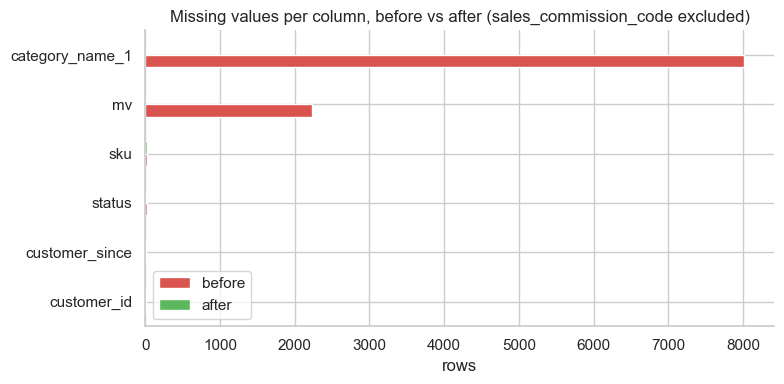

In [52]:
after_missing = clean.isna().sum()
cmp_cols = [c for c in before_missing.index if before_missing[c] > 0 and c in after_missing.index and c != "sales_commission_code"]
dq = pd.DataFrame({"before": before_missing[cmp_cols], "after": after_missing[cmp_cols]}).sort_values("before")
dq.plot.barh(figsize=(8, 4), color=["#d9534f", "#5cb85c"])
plt.title("Missing values per column, before vs after (sales_commission_code excluded)"); plt.xlabel("rows")
plt.tight_layout(); plt.show()

`sales_commission_code` (about 476k missing) is left out of the chart because it would hide the rest, and it stays missing on purpose: most orders simply have no commission. The other columns are fixed or reduced to an `Unknown` label.

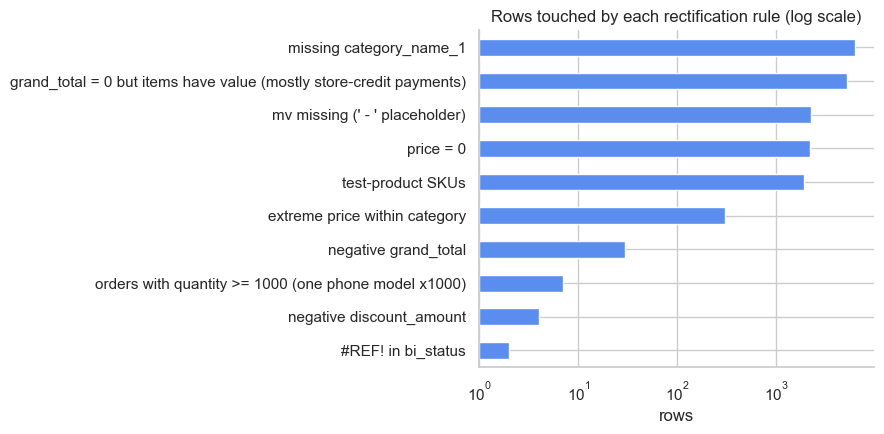

In [53]:
fixes = pd.DataFrame(rect_log).sort_values("rows_affected")
fixes.plot.barh(x="issue", y="rows_affected", figsize=(9, 4.5), legend=False, color="#5b8def", log=True)
plt.title("Rows touched by each rectification rule (log scale)"); plt.xlabel("rows"); plt.ylabel("")
plt.tight_layout(); plt.show()

### 3.2 Sales over time

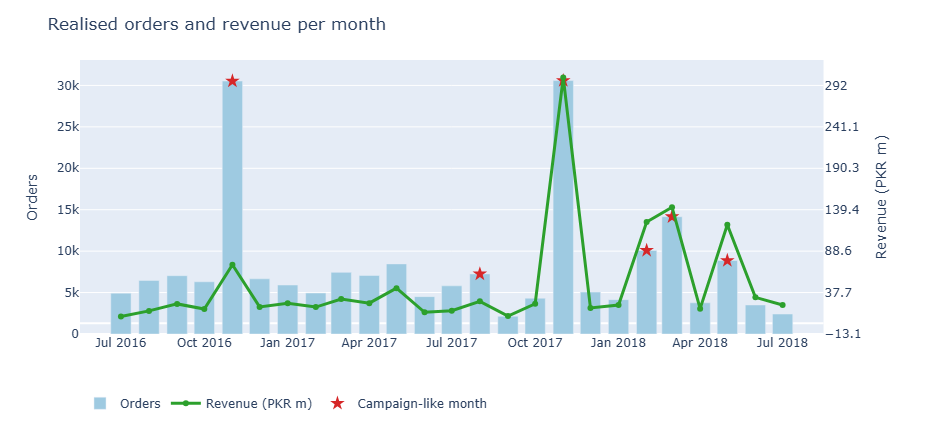

In [54]:
fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Bar(x=trend.month, y=trend.orders, name="Orders", marker_color="#9ecae1"), secondary_y=False)
fig.add_trace(go.Scatter(x=trend.month, y=trend.revenue / 1e6, name="Revenue (PKR m)", mode="lines+markers",
                         line=dict(color="#2ca02c", width=3)), secondary_y=True)
camp = trend[trend.campaign]
fig.add_trace(go.Scatter(x=camp.month, y=camp.orders, mode="markers", name="Campaign-like month",
                         marker=dict(color="#d62728", size=11, symbol="star")), secondary_y=False)
fig.update_layout(title="Realised orders and revenue per month", height=430, legend=dict(orientation="h", y=-0.2),
                  margin=dict(t=60, b=40))
fig.update_yaxes(title_text="Orders", secondary_y=False); fig.update_yaxes(title_text="Revenue (PKR m)", secondary_y=True)
fig.show()

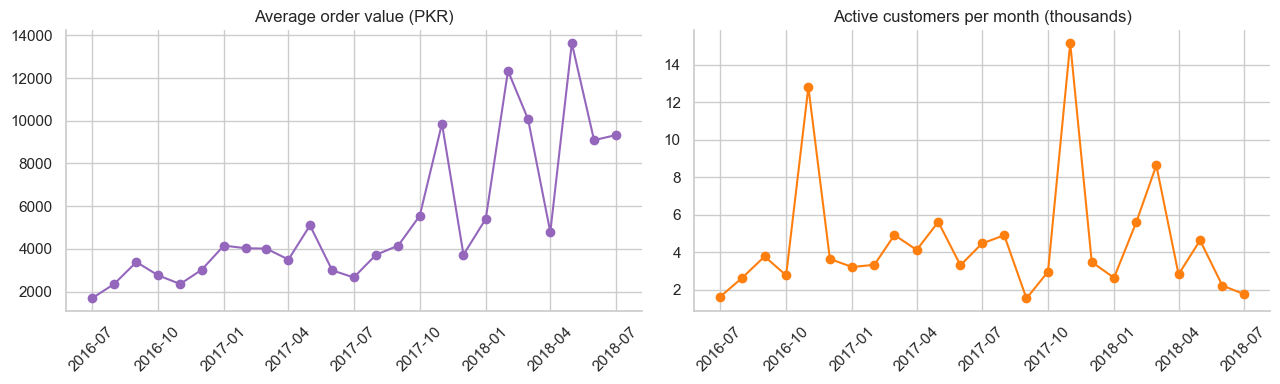

In [55]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(trend.month, trend.aov, marker="o", color="tab:purple"); ax[0].set_title("Average order value (PKR)")
ax[1].plot(trend.month, trend.customers / 1e3, marker="o", color="tab:orange"); ax[1].set_title("Active customers per month (thousands)")
for a in ax: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

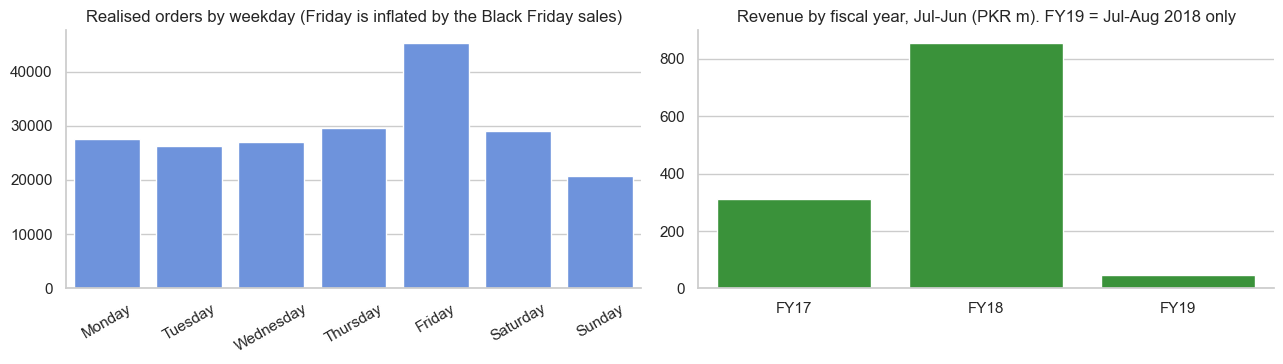

In [56]:
wk = real.groupby(real.created_at.dt.day_name()).size().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
sns.barplot(x=wk.index, y=wk.values, ax=ax[0], color="#5b8def"); ax[0].set_title("Realised orders by weekday (Friday is inflated by the Black Friday sales)"); ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=30)
by_fy = real.assign(FY=real.created_at.apply(lambda d: f"FY{(d.year + (d.month >= 7)) % 100}")).groupby("FY").revenue.sum() / 1e6
sns.barplot(x=by_fy.index, y=by_fy.values, ax=ax[1], color="#2ca02c"); ax[1].set_title("Revenue by fiscal year, Jul-Jun (PKR m). FY19 = Jul-Aug 2018 only"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

### 3.3 Categories

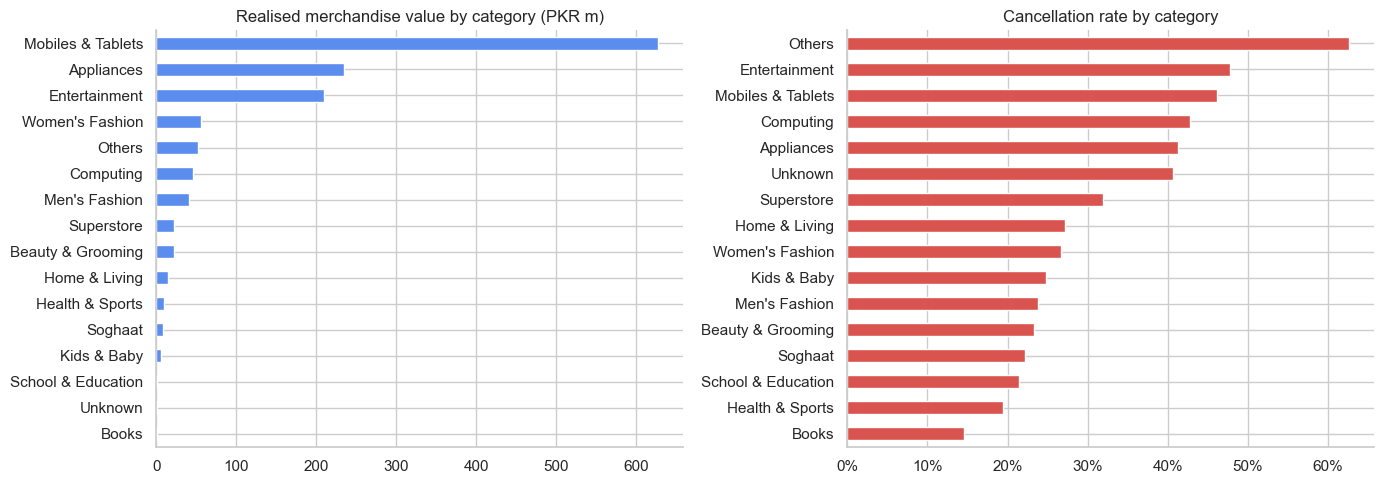

In [57]:
items = clean[(clean.status_group == "Realised") & (~clean.is_suspect_order) & (clean.price > 0)].copy()
items["gmv"] = items["item_value"]
cat = (items.groupby("category_name_1").agg(items=("item_id", "size"), gmv=("gmv", "sum"))
       .assign(share=lambda d: d.gmv / d.gmv.sum()).sort_values("gmv", ascending=False))
cancel = clean.groupby("category_name_1").status_group.apply(lambda s: (s == "Cancelled").mean()).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
(cat.gmv.sort_values() / 1e6).plot.barh(ax=ax[0], color="#5b8def"); ax[0].set_title("Realised merchandise value by category (PKR m)"); ax[0].set_ylabel("")
cancel.plot.barh(ax=ax[1], color="#d9534f"); ax[1].set_title("Cancellation rate by category"); ax[1].set_ylabel("")
ax[1].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.tight_layout(); plt.show()

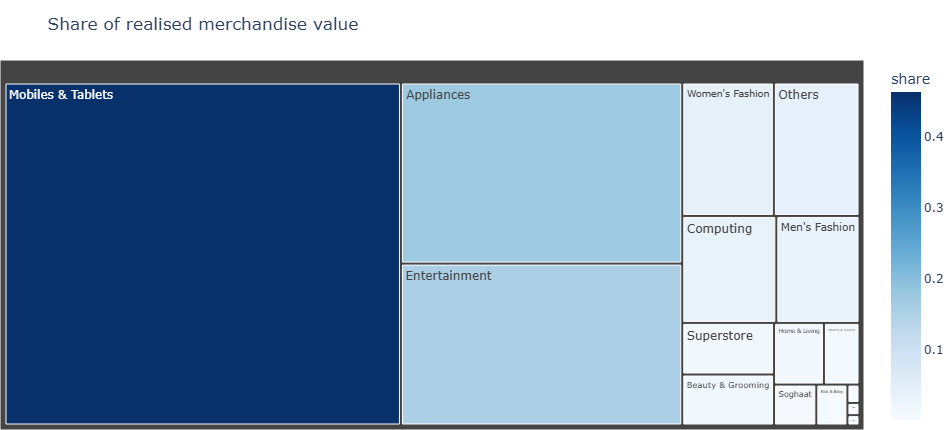

In [58]:
fig = px.treemap(cat.reset_index(), path=["category_name_1"], values="gmv", color="share",
                 color_continuous_scale="Blues", title="Share of realised merchandise value")
fig.update_layout(height=430, margin=dict(t=60, l=0, r=0, b=0)); fig.show()

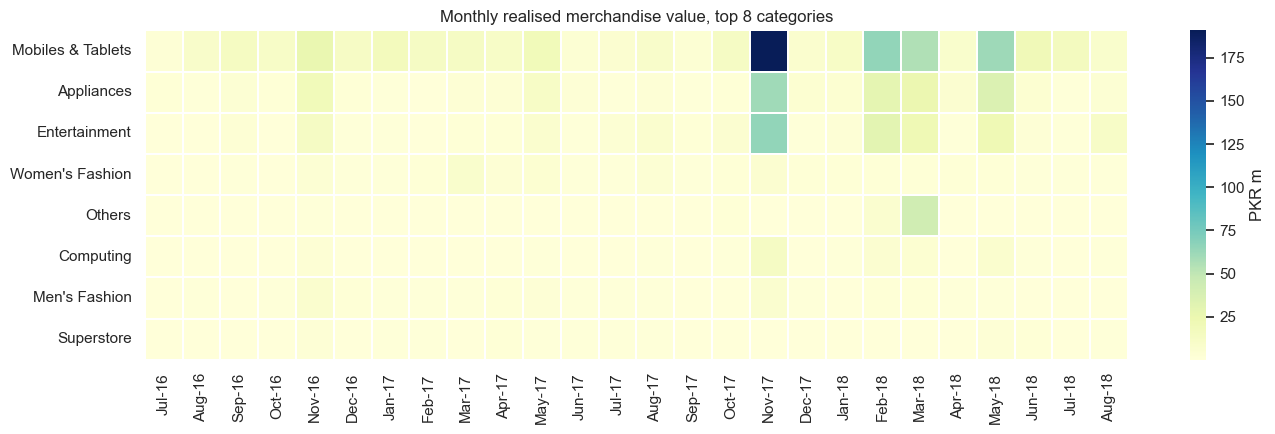

In [59]:
top8 = cat.head(8).index
hm = (items[items.category_name_1.isin(top8)]
      .assign(month=lambda d: d.created_at.dt.to_period("M").dt.to_timestamp())
      .pivot_table(index="category_name_1", columns="month", values="gmv", aggfunc="sum") / 1e6)
hm.columns = [c.strftime("%b-%y") for c in hm.columns]
plt.figure(figsize=(14, 4.5)); sns.heatmap(hm.loc[top8], cmap="YlGnBu", linewidths=.3, cbar_kws={"label": "PKR m"})
plt.title("Monthly realised merchandise value, top 8 categories"); plt.ylabel(""); plt.xlabel("")
plt.tight_layout(); plt.show()

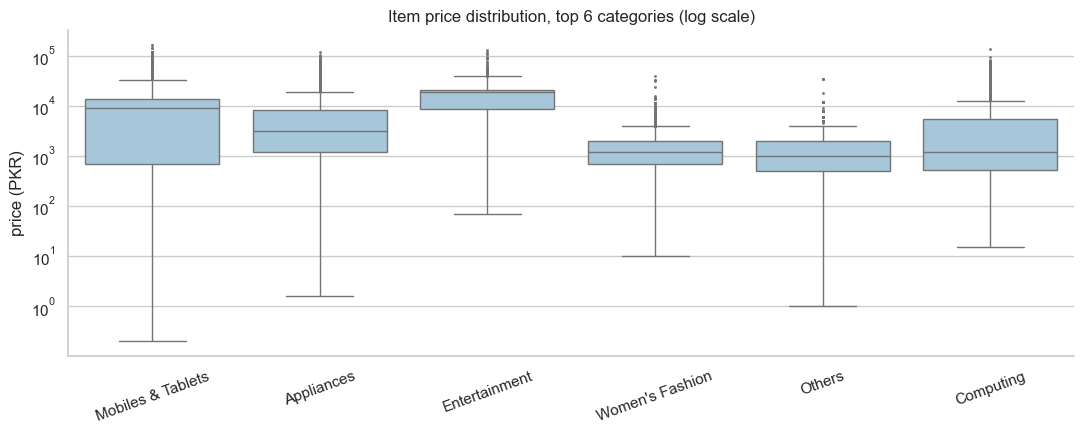

In [60]:
top6 = cat.head(6).index
sample = items[items.category_name_1.isin(top6)].sample(min(60000, len(items)), random_state=1)
plt.figure(figsize=(11, 4.5))
sns.boxplot(data=sample, x="category_name_1", y="price", order=top6, color="#9ecae1", fliersize=1)
plt.yscale("log"); plt.title("Item price distribution, top 6 categories (log scale)"); plt.xlabel(""); plt.ylabel("price (PKR)")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

### 3.4 Order status and payment

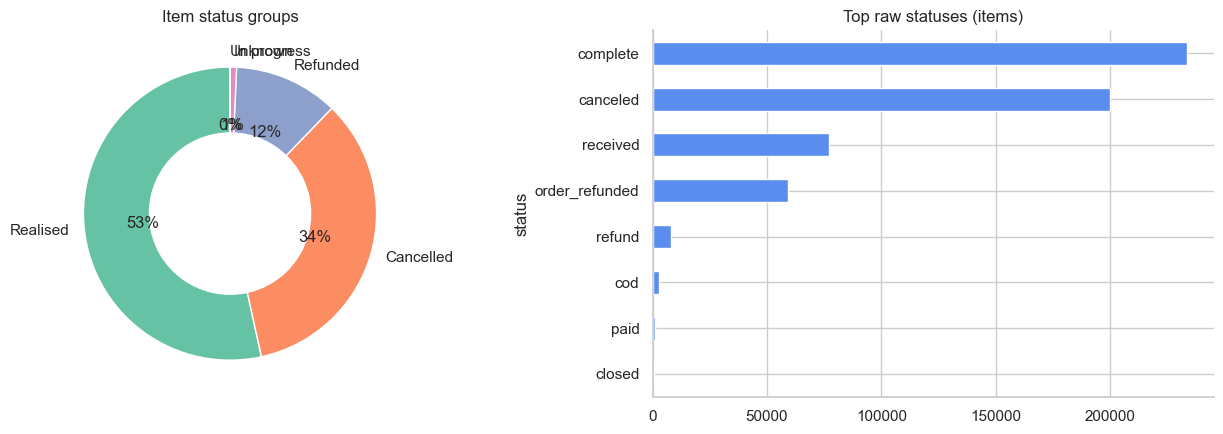

In [61]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sg = clean.status_group.value_counts()
ax[0].pie(sg.values, labels=sg.index, autopct="%1.0f%%", startangle=90, wedgeprops=dict(width=.45), colors=sns.color_palette("Set2"))
ax[0].set_title("Item status groups")
st = clean.status.value_counts().head(8).sort_values()
st.plot.barh(ax=ax[1], color="#5b8def"); ax[1].set_title("Top raw statuses (items)")
plt.tight_layout(); plt.show()

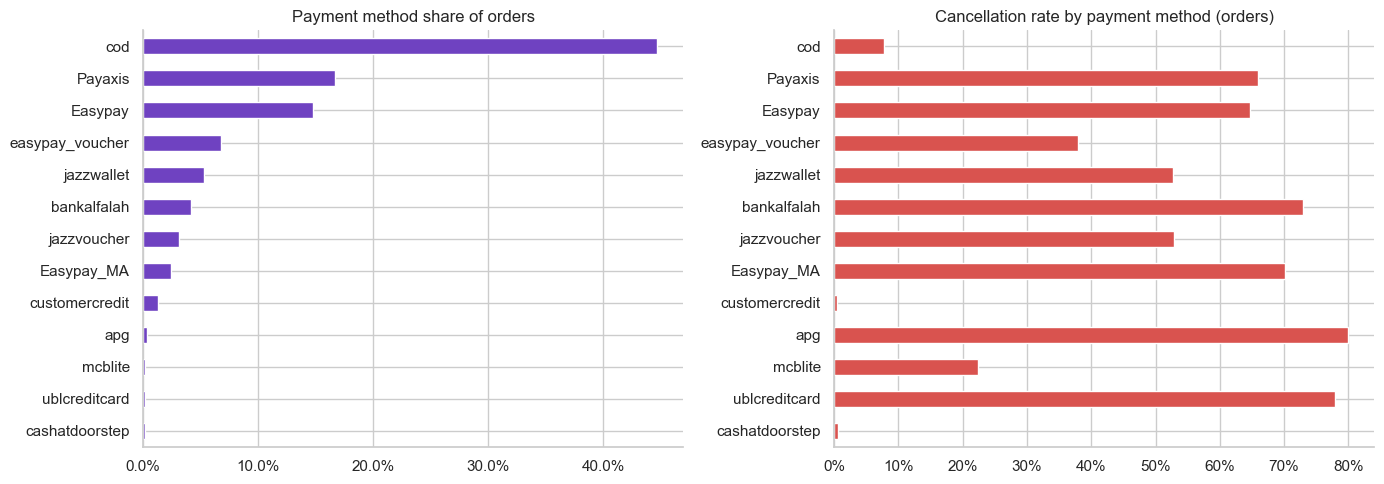

In [62]:
pay = (orders.groupby("payment_method")
       .agg(orders=("increment_id", "size"), cancel_rate=("status_group", lambda s: (s == "Cancelled").mean()))
       .query("orders >= 500").sort_values("orders"))
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
(pay.orders / pay.orders.sum()).plot.barh(ax=ax[0], color="#6f42c1"); ax[0].set_title("Payment method share of orders")
ax[0].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1)); ax[0].set_ylabel("")
pay.cancel_rate.plot.barh(ax=ax[1], color="#d9534f"); ax[1].set_title("Cancellation rate by payment method (orders)")
ax[1].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1)); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

Some online payment methods have a much higher cancellation rate than COD. One possible reason is that failed online payments are recorded as cancelled orders, but the data cannot prove this. Treat it as a question for the business, not a conclusion.

### 3.5 Orders and customers

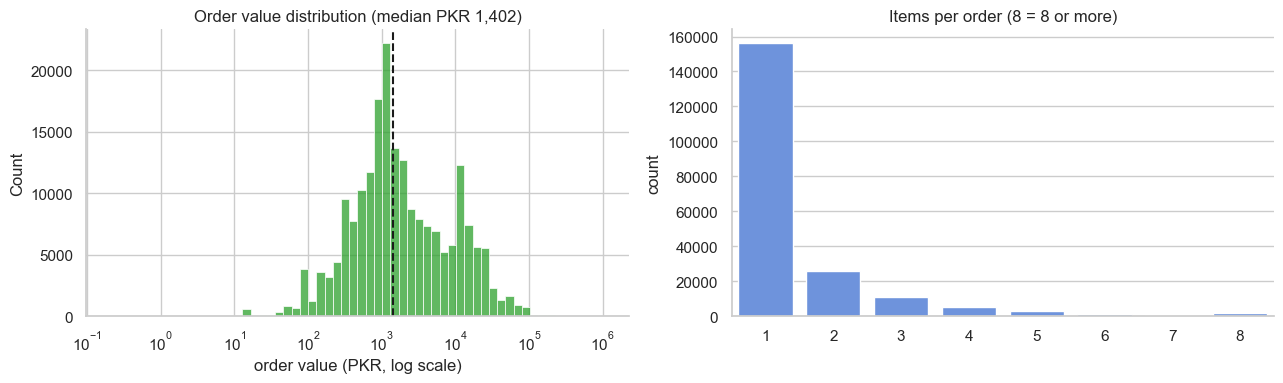

In [63]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
rv = real.revenue[real.revenue > 0]
sns.histplot(rv, log_scale=True, bins=60, ax=ax[0], color="#2ca02c")
ax[0].axvline(rv.median(), color="k", ls="--"); ax[0].set_title(f"Order value distribution (median PKR {rv.median():,.0f})"); ax[0].set_xlabel("order value (PKR, log scale)")
sns.countplot(x=real["items"].clip(upper=8), ax=ax[1], color="#5b8def"); ax[1].set_title("Items per order (8 = 8 or more)"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

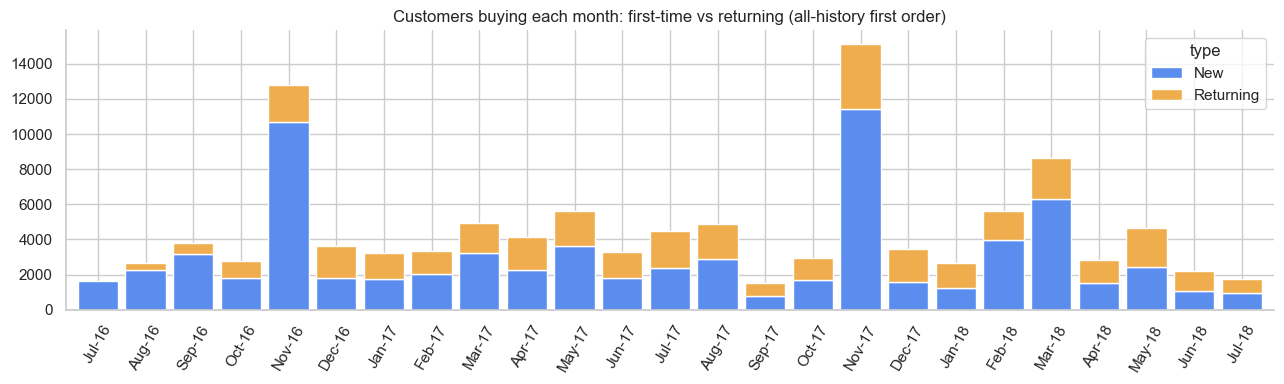

In [64]:
first_month = orders.groupby("customer_id").month.min().rename("first_month")
r2 = real.join(first_month, on="customer_id")
r2["type"] = np.where(r2.month == r2.first_month, "New", "Returning")
nr = r2.groupby(["month", "type"]).customer_id.nunique().unstack(fill_value=0)
nr = nr[nr.index < "2018-08-01"]
nr.index = nr.index.strftime("%b-%y")
nr.plot.bar(stacked=True, figsize=(13, 4), color=["#5b8def", "#f0ad4e"], width=.85)
plt.title("Customers buying each month: first-time vs returning (all-history first order)")
plt.xticks(rotation=60); plt.xlabel(""); plt.tight_layout(); plt.show()

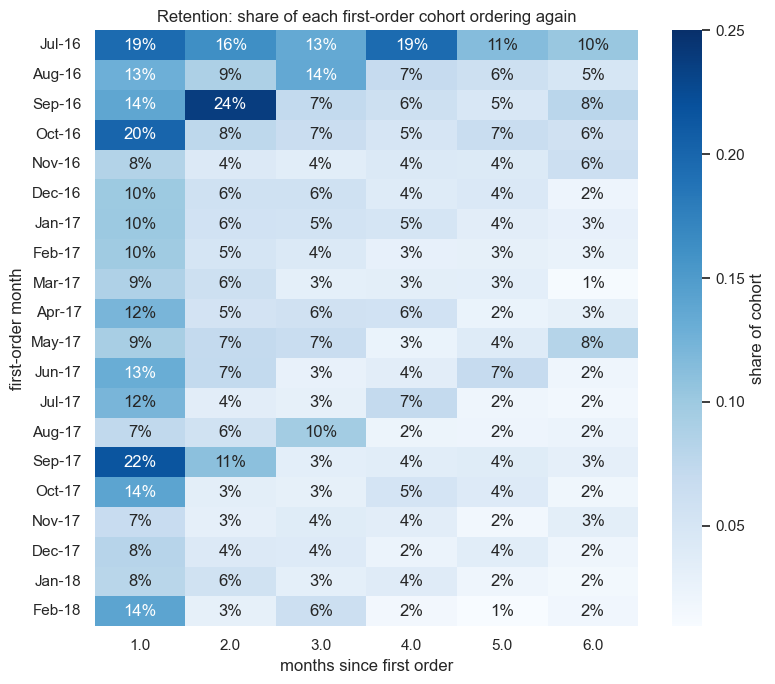

In [65]:
o2 = orders.join(first_month, on="customer_id")
o2["age"] = (o2.month.dt.year - o2.first_month.dt.year) * 12 + (o2.month.dt.month - o2.first_month.dt.month)
ret = o2.groupby(["first_month", "age"]).customer_id.nunique().unstack()
ret = ret.div(ret[0], axis=0).iloc[:, 1:7]
ret = ret[ret.index < "2018-03-01"]
ret.index = ret.index.strftime("%b-%y")
plt.figure(figsize=(8, 7)); sns.heatmap(ret, annot=True, fmt=".0%", cmap="Blues", vmax=.25, cbar_kws={"label": "share of cohort"})
plt.title("Retention: share of each first-order cohort ordering again"); plt.xlabel("months since first order"); plt.ylabel("first-order month")
plt.tight_layout(); plt.show()

### 3.6 Key takeaways (computed from the data)

In [66]:
yoy = trend.set_index("month").orders
jj = pd.DataFrame({"2017": yoy["2017-06":"2017-07"].values, "2018": yoy["2018-06":"2018-07"].values}, index=["Jun", "Jul"])
top_cat = cat.index[0]
novs = trend[trend.month.dt.month == 11]
best_ret = ret.iloc[:, 0].idxmax(); worst_ret = ret.iloc[:, 0].idxmin()

print(f"Realised orders: {len(real):,} | realised revenue: PKR {real.revenue.sum()/1e9:.2f} bn | median order PKR {real.revenue.median():,.0f}")
print(f"Revenue is concentrated: {top_cat} = {cat.share.iloc[0]:.0%} of value, top 3 categories = {cat.share.head(3).sum():.0%}")
print(f"November spikes: {', '.join(f'{d:%b-%y} ({o:,} orders)' for d, o in zip(novs.month, novs.orders))}")
print(f"Campaign-like months detected: {', '.join(d.strftime('%b-%y') for d in trend[trend.campaign].month)}")
print(f"Organic demand, Jun-Jul 2018 vs 2017: {(jj['2018'].sum()/jj['2017'].sum()-1):+.0%}")
print(f"Items cancelled: {(clean.status_group=='Cancelled').mean():.0%} | refunded: {(clean.status_group=='Refunded').mean():.0%}")
print(f"COD share of orders: {(orders.payment_method=='cod').mean():.0%}")
print(f"Month-1 retention ranges from {ret.iloc[:,0].min():.0%} ({worst_ret}) to {ret.iloc[:,0].max():.0%} ({best_ret})")

Realised orders: 205,572 | realised revenue: PKR 1.22 bn | median order PKR 1,400
Revenue is concentrated: Mobiles & Tablets = 46% of value, top 3 categories = 79%
November spikes: Nov-16 (30,528 orders), Nov-17 (30,586 orders)
Campaign-like months detected: Nov-16, Aug-17, Nov-17, Feb-18, Mar-18, May-18
Organic demand, Jun-Jul 2018 vs 2017: -43%
Items cancelled: 34% | refunded: 12%
COD share of orders: 45%
Month-1 retention ranges from 7% (Nov-17) to 22% (Sep-17)


In [68]:

# Check the available historical period

print("First transaction date:", clean["created_at"].min())
print("Last transaction date:", clean["created_at"].max())

monthly_coverage = (
    clean.assign(
        month=clean["created_at"].dt.to_period("M")
    )
    .groupby("month")
    .size()
)

print("\nNumber of months:", len(monthly_coverage))
print("\nRecords per month:")
display(monthly_coverage.to_frame("item_rows"))


First transaction date: 2016-07-01 00:00:00
Last transaction date: 2018-08-28 00:00:00

Number of months: 26

Records per month:


,item_rows
month,
2016-07,8745
2016-08,11521
2016-09,15422
2016-10,13107
2016-11,70942
2016-12,13393
2017-01,13125
2017-02,11764
2017-03,19394


In [70]:

# 1. Check the status of each category
status_category = pd.crosstab(
    clean["status"],
    clean["category_name_1"],
    dropna=False
)

display(status_category)

# 2. Compare item-row counts by month
monthly_items = (
    clean.assign(
        month_start=pd.to_datetime(clean["created_at"]).dt.to_period("M")
    )
    .groupby("month_start")
    .agg(
        item_rows=("item_id", "count"),
        unique_orders=("increment_id", "nunique"),
        categories=("category_name_1", "nunique")
    )
    .reset_index()
)

display(monthly_items)

# 3. Inspect discount recording
discount_check = (
    clean.groupby("increment_id")
    .agg(
        item_rows=("item_id", "count"),
        unique_discounts=("discount_amount", "nunique"),
        discount_sum=("discount_amount", "sum"),
        discount_first=("discount_amount", "first"),
        order_total=("grand_total", "first")
    )
    .reset_index()
)

display(
    discount_check.sort_values(
        "item_rows", ascending=False
    ).head(20)
)


category_name_1,Appliances,Beauty & Grooming,Books,Computing,Entertainment,Health & Sports,Home & Living,Kids & Baby,Men's Fashion,Mobiles & Tablets,Others,School & Education,Soghaat,Superstore,Unknown,Women's Fashion
status,,,,,,,,,,,,,,,,
canceled,21628,9685,272,6818,12578,3583,7199,4085,22024,54195,19130,749,7593,14052,440,15968
closed,92,57,7,16,7,15,15,5,65,63,2,1,16,10,1,121
cod,109,329,81,66,21,76,394,147,598,163,68,21,111,171,6,495
complete,20716,20736,910,5745,9328,8622,11157,7028,40322,42795,3595,1592,20003,16938,404,23736
exchange,0,0,0,1,0,0,0,0,1,1,0,0,0,0,0,1
fraud,0,0,0,1,2,0,1,0,0,6,0,0,0,0,0,0
holded,3,3,0,2,2,0,2,0,5,10,0,1,3,0,0,0
order_refunded,4694,3613,223,1640,2095,2296,2500,1834,14869,10999,1413,497,1856,2131,169,8208
paid,43,114,12,18,20,18,78,63,105,80,32,5,71,364,1,124


,month_start,item_rows,unique_orders,categories
0,2016-07,8745,7190,16
1,2016-08,11521,9933,16
2,2016-09,15422,13125,16
3,2016-10,13107,10867,16
4,2016-11,70942,54876,16
5,2016-12,13393,10935,16
6,2017-01,13125,10005,16
7,2017-02,11764,8661,16
8,2017-03,19394,13411,16
9,2017-04,21605,12179,16


,increment_id,item_rows,unique_discounts,discount_sum,discount_first,order_total
309479,100266667,72,1,0.00,0.00,44402.00
329458,100286851,47,1,0.00,0.00,57690.00
151767,100346364,45,15,112.30,1.00,1010.70
352884,100476608,43,1,0.00,0.00,150.00
380629,100535753,41,1,222353.25,5423.25,30731.75
380615,100535739,40,1,214584.00,5364.60,30399.40
380625,100535749,40,1,217254.00,5431.35,30777.65
380620,100535744,40,1,218484.00,5462.10,30951.90
105618,100299466,40,1,0.00,0.00,12105.00
138798,100333210,39,1,0.00,0.00,12000.00


In [72]:

order_id = 100535753

order_details = clean.loc[
    clean["increment_id"] == order_id,
    [
        "increment_id",
        "item_id",
        "sku",
        "category_name_1",
        "status",
        "price",
        "qty_ordered",
        "discount_amount",
        "grand_total"
    ]
]

display(order_details)


,increment_id,item_id,sku,category_name_1,status,price,qty_ordered,discount_amount,grand_total


In [73]:

discount_rows = clean.loc[
    clean["discount_amount"].fillna(0) != 0,
    [
        "increment_id",
        "price",
        "qty_ordered",
        "discount_amount",
        "grand_total",
        "status"
    ]
].copy()

discount_rows["discount_to_price_ratio"] = (
    discount_rows["discount_amount"] /
    discount_rows["price"].replace(0, float("nan"))
)

display(discount_rows.head(20))

print("Non-zero discount rows:", len(discount_rows))
print(
    "Discounts larger than item price:",
    (discount_rows["discount_amount"] > discount_rows["price"]).sum()
)


,increment_id,price,qty_ordered,discount_amount,grand_total,status,discount_to_price_ratio
3,100147446,360.0,1.0,300.00,60.0,complete,0.833333
6,100147449,360.0,1.0,300.00,60.0,complete,0.833333
33,100147468,165.0,1.0,82.50,300.0,refund,0.500000
34,100147468,435.0,1.0,217.50,300.0,refund,0.500000
38,100147471,90.0,1.0,19.15,740.0,complete,0.212778
39,100147471,850.0,1.0,180.85,740.0,complete,0.212765
43,100147474,143.0,1.0,77.72,168.0,complete,0.543497
44,100147474,225.0,1.0,122.28,168.0,complete,0.543467
195,100147590,350.0,1.0,200.00,150.0,complete,0.571429
201,100147597,265.0,1.0,149.30,155.0,complete,0.563396


Non-zero discount rows: 207943
Discounts larger than item price: 13150


In [74]:

order_id = "100535753"

print("clean column type:", clean["increment_id"].dtype)
print("Original df column type:", df["increment_id"].dtype)

print(
    "Matches in clean:",
    clean["increment_id"].astype(str).str.strip().eq(order_id).sum()
)

print(
    "Matches in df:",
    df["increment_id"].astype(str).str.strip().eq(order_id).sum()
)

# Display details from clean if found
order_details = clean.loc[
    clean["increment_id"].astype(str).str.strip().eq(order_id),
    [
        "increment_id", "item_id", "sku", "category_name_1",
        "status", "price", "qty_ordered",
        "discount_amount", "grand_total"
    ]
]

display(order_details)


clean column type: object
Original df column type: object
Matches in clean: 41
Matches in df: 41


,increment_id,item_id,sku,category_name_1,status,price,qty_ordered,discount_amount,grand_total
544136,100535753,860054.0,WOFSIT5ACB1AB1DF012,Women's Fashion,canceled,629.0,2.0,5423.25,30731.75
544137,100535753,860055.0,WOFSIT5AB240DAC8743,Women's Fashion,canceled,699.0,1.0,5423.25,30731.75
544138,100535753,860056.0,WOFSIT5ACB1AB15B0AE,Women's Fashion,canceled,629.0,1.0,5423.25,30731.75
544139,100535753,860057.0,WOFSIT5A993A4FCC1D2,Women's Fashion,canceled,629.0,1.0,5423.25,30731.75
544140,100535753,860058.0,WOFSIT5ABB3A7AE49F6,Women's Fashion,canceled,699.0,1.0,5423.25,30731.75
544141,100535753,860059.0,WOFSIT5A993A5C0358A,Women's Fashion,canceled,629.0,1.0,5423.25,30731.75
544142,100535753,860060.0,WOFSIT5ACB1AAE4CA56,Women's Fashion,canceled,629.0,1.0,5423.25,30731.75
544143,100535753,860061.0,WOFSIT5A993A74986E1,Women's Fashion,canceled,629.0,1.0,5423.25,30731.75
544144,100535753,860062.0,WOFSIT5A993A84A9D32,Women's Fashion,canceled,629.0,1.0,5423.25,30731.75
544145,100535753,860063.0,WOFSIT5A993A516A802,Women's Fashion,canceled,629.0,1.0,5423.25,30731.75
